In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

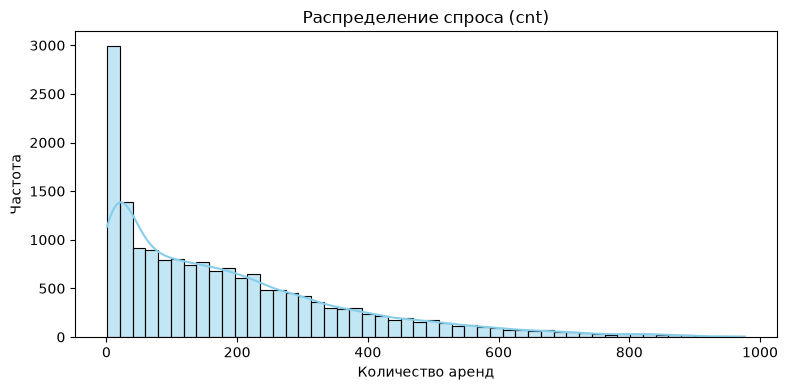

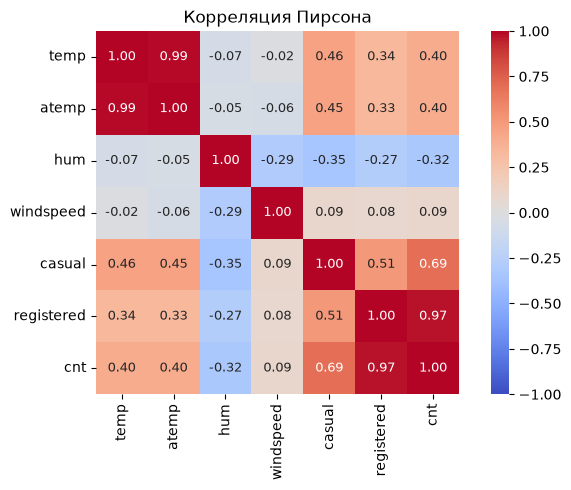

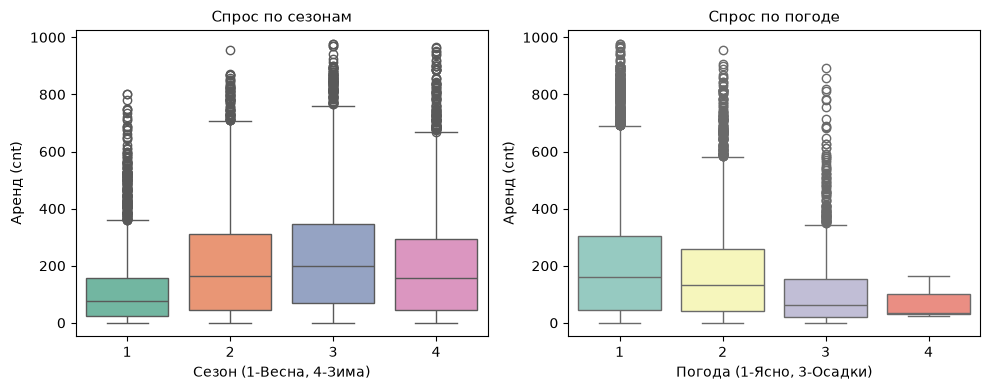

In [2]:
# 1. Загрузка данных
df = pd.read_csv('hour.csv')
df['dteday'] = pd.to_datetime(df['dteday'])

# ==========================================
# 1. Распределение целевой переменной (Компактный)
# ==========================================
plt.figure(figsize=(8, 4)) # Уменьшено с (10, 5)
sns.histplot(df['cnt'], kde=True, bins=50, color='skyblue')
plt.title('Распределение спроса (cnt)', fontsize=12)
plt.xlabel('Количество аренд')
plt.ylabel('Частота')
plt.tight_layout()
plt.show()

# ==========================================
# 2. Корреляционная матрица (Компактная)
# ==========================================
continuous_cols = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
plt.figure(figsize=(7, 5)) # Уменьшено с (12, 8)
corr_matrix = df[continuous_cols].corr(method='pearson')
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
            square=True, vmin=-1, vmax=1, annot_kws={"size": 9}) # Уменьшен шрифт цифр
plt.title('Корреляция Пирсона', fontsize=12)
plt.tight_layout()
plt.show()

# ==========================================
# 3. Влияние категорий (Компактные Boxplot'ы)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(10, 4)) # Уменьшено с (16, 6)

sns.boxplot(x='season', y='cnt', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Спрос по сезонам', fontsize=11)
axes[0].set_xlabel('Сезон (1-Весна, 4-Зима)')
axes[0].set_ylabel('Аренд (cnt)')

sns.boxplot(x='weathersit', y='cnt', data=df, ax=axes[1], palette='Set3')
axes[1].set_title('Спрос по погоде', fontsize=11)
axes[1].set_xlabel('Погода (1-Ясно, 3-Осадки)')
axes[1].set_ylabel('Аренд (cnt)')

plt.tight_layout()
plt.show()

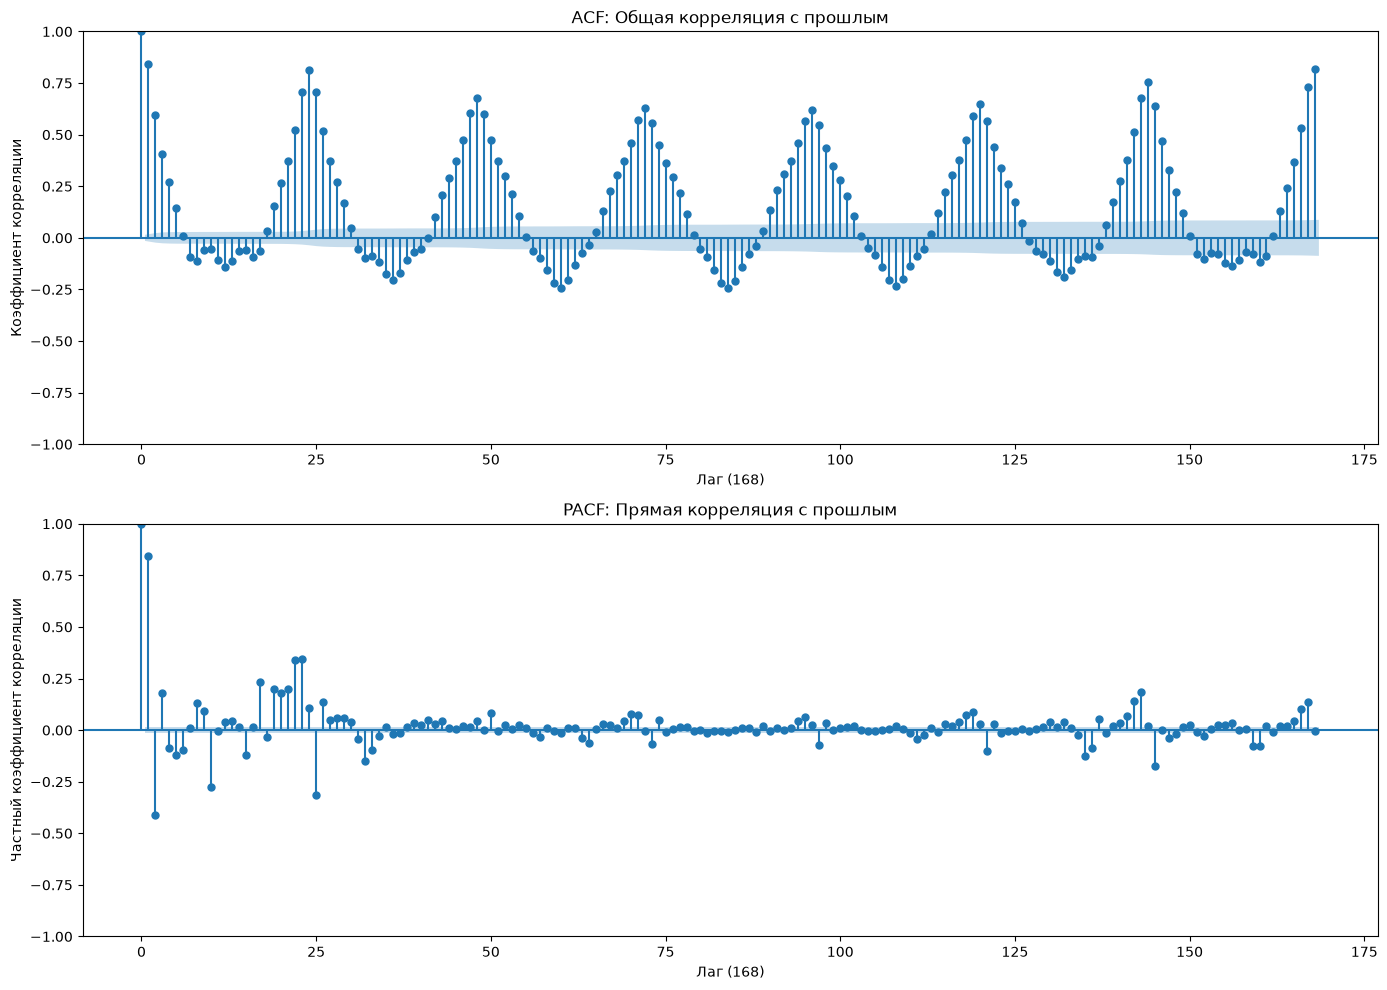

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import seaborn as sns

# 1. Загрузка и подготовка данных
df = pd.read_csv('hour.csv')

# Создаем полноценный datetime-индекс: дата + час
df['datetime'] = pd.to_datetime(df['dteday']) + pd.to_timedelta(df['hr'], unit='h')
df.set_index('datetime', inplace=True)

# Нас интересует целевая переменная - общее количество аренд
series = df['cnt']

# 2. Построение графиков ACF и PACF
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

# График ACF
plot_acf(series, lags=168, ax=ax1, title='ACF: Общая корреляция с прошлым', alpha=0.05)
ax1.set_xlabel('Лаг (168)')
ax1.set_ylabel('Коэффициент корреляции')

# График PACF
plot_pacf(series, lags=168, ax=ax2, title='PACF: Прямая корреляция с прошлым', alpha=0.05)
ax2.set_xlabel('Лаг (168)')
ax2.set_ylabel('Частный коэффициент корреляции')

plt.tight_layout()
plt.show()

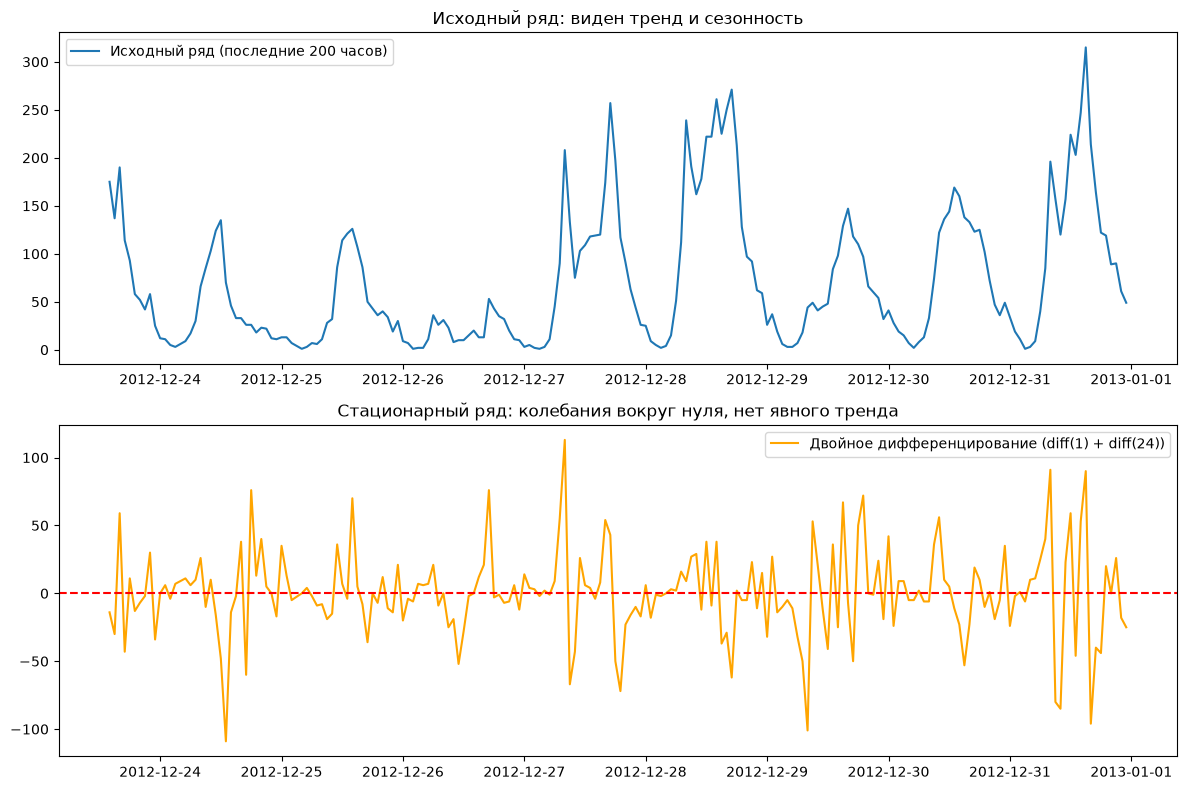

ADF Statistic: -31.4235
p-value: 0.0000
✅ Ряд СТАЦИОНАРЕН. Можно строить SARIMA.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# 1. Подготовка данных
df = pd.read_csv('hour.csv')
df['datetime'] = pd.to_datetime(df['dteday']) + pd.to_timedelta(df['hr'], unit='h')
df.set_index('datetime', inplace=True)
df = df.sort_index()

# Исходный ряд
y = df['cnt']

# 2. Дифференцирование
# Шаг 1: Убираем тренд (разность с предыдущим часом)
y_diff1 = y.diff(1)

# Шаг 2: Убираем суточную сезонность (разность с тем же часом вчера)
# Применяем к уже дифференцированному ряду
y_diff_seasonal = y_diff1.diff(24)

# Удаляем NaN, которые появились в начале из-за операции diff()
y_final = y_diff_seasonal.dropna()

# 3. Визуальная проверка
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
axes[0].plot(y.tail(200), label='Исходный ряд (последние 200 часов)')
axes[0].set_title('Исходный ряд: виден тренд и сезонность')
axes[0].legend()

axes[1].plot(y_final.tail(200), label='Двойное дифференцирование (diff(1) + diff(24))', color='orange')
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Стационарный ряд: колебания вокруг нуля, нет явного тренда')
axes[1].legend()
plt.tight_layout()
plt.show()

# 4. Статистическая проверка (Тест Дики-Фуллера)
# H0: ряд нестационарен. Если p-value < 0.05, отвергаем H0 (ряд стационарен)
result = adfuller(y_final)
print(f'ADF Statistic: {result[0]:.4f}')
print(f'p-value: {result[1]:.4f}')
if result[1] < 0.05:
    print("✅ Ряд СТАЦИОНАРЕН. Можно строить SARIMA.")
else:
    print("❌ Ряд НЕ СТАЦИОНАРЕН. Нужно дополнительное преобразование.")

### SARIMA

Новый индекс регулярный: <Hour>
Train: 17376 часов, Test: 168 часов

Обучение SARIMA... (это может занять 1-3 минуты)


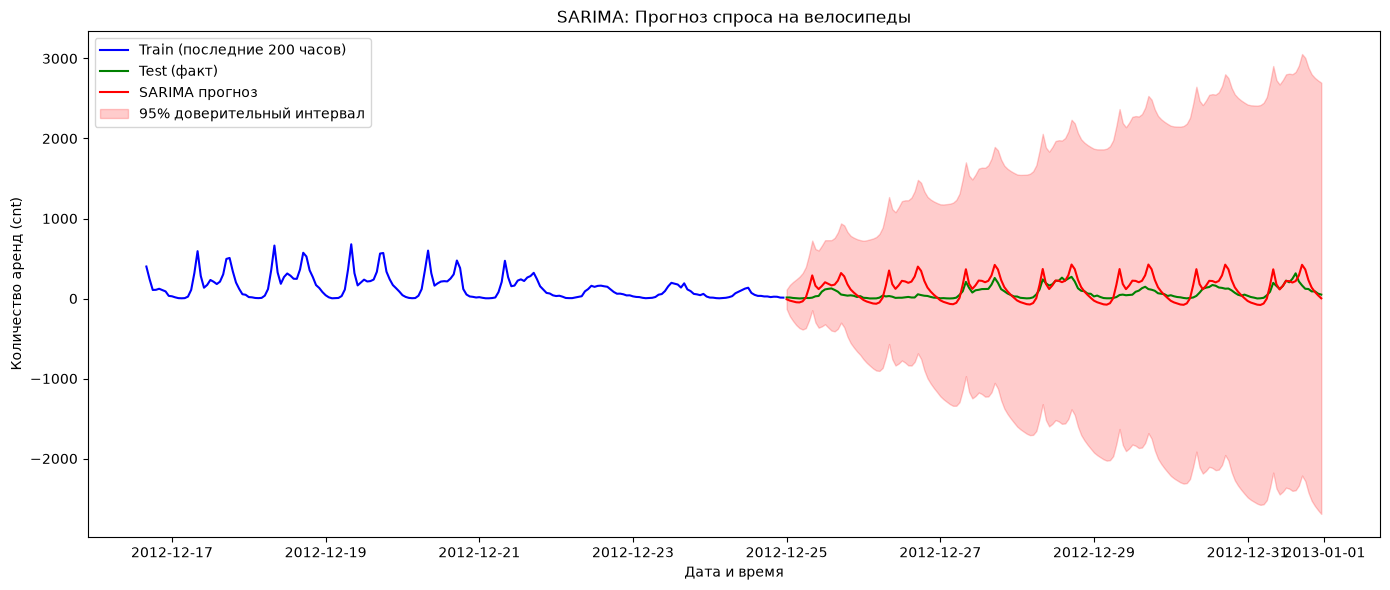


=== Метрики SARIMA ===
MAE:  91.59
RMSE: 119.98
MAPE: 6.20%


In [5]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error
import matplotlib.pyplot as plt

# 1. Загрузка и подготовка данных
df = pd.read_csv('hour.csv')
df['datetime'] = pd.to_datetime(df['dteday']) + pd.to_timedelta(df['hr'], unit='h')
df.set_index('datetime', inplace=True)
df = df.sort_index()

# Целевая переменная
y = df['cnt']

# ==========================================
# !!! ИСПРАВЛЕНИЕ: Явно задаем частоту данных !!!
# 'H' означает Hourly (почасовые данные). 
# Без этого statsmodels не сможет сделать прогноз на future steps.
# ==========================================
# Создаем идеальный почасовой индекс от начала до конца данных
full_index = pd.date_range(start=df.index.min(), end=df.index.max(), freq='1h')

# Переиндексируем данные по этому идеальному индексу
y_regular = y.reindex(full_index)

# Заполняем пропуски
y_regular = y_regular.interpolate(method='linear')

print(f"Новый индекс регулярный: {y_regular.index.freq}")  # Должно вывести <Hour>

# 2. Разделение на train/test (последние 168 часов = 7 дней для теста)
train_size = len(y_regular) - 168
train = y_regular[:train_size]
test = y_regular[train_size:]

print(f"Train: {len(train)} часов, Test: {len(test)} часов")

# 3. Обучение SARIMA
print("\nОбучение SARIMA... (это может занять 1-3 минуты)")
model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 24),
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = model.fit(disp=False)

# 4. Прогноз (теперь эта строка сработает без ошибок)
forecast = results.get_forecast(steps=len(test))
forecast_values = forecast.predicted_mean
confidence_intervals = forecast.conf_int()

# 5. Оценка качества
mse = mean_squared_error(test, forecast_values)
rmse = np.sqrt(mse)
mae = mean_absolute_error(test, forecast_values)

mae_SARIMA = mean_absolute_error(test, forecast_values)
rmse_SARIMA = root_mean_squared_error(test, forecast_values)
mape_SARIMA = mean_absolute_percentage_error(test, forecast_values)



# 6. Визуализация
plt.figure(figsize=(14, 6))
plt.plot(train.tail(200), label='Train (последние 200 часов)', color='blue')
plt.plot(test, label='Test (факт)', color='green')
plt.plot(forecast_values, label='SARIMA прогноз', color='red')
plt.fill_between(
    forecast_values.index,
    confidence_intervals.iloc[:, 0],
    confidence_intervals.iloc[:, 1],
    color='red',
    alpha=0.2,
    label='95% доверительный интервал'
)
plt.title('SARIMA: Прогноз спроса на велосипеды')
plt.xlabel('Дата и время')
plt.ylabel('Количество аренд (cnt)')
plt.legend()
plt.tight_layout()
plt.show()


print(f"\n=== Метрики SARIMA ===")
print(f'MAE:  {mae_SARIMA:.2f}')
print(f'RMSE: {rmse_SARIMA:.2f}')
print(f'MAPE: {mape_SARIMA:.2f}%')

### LightGBM

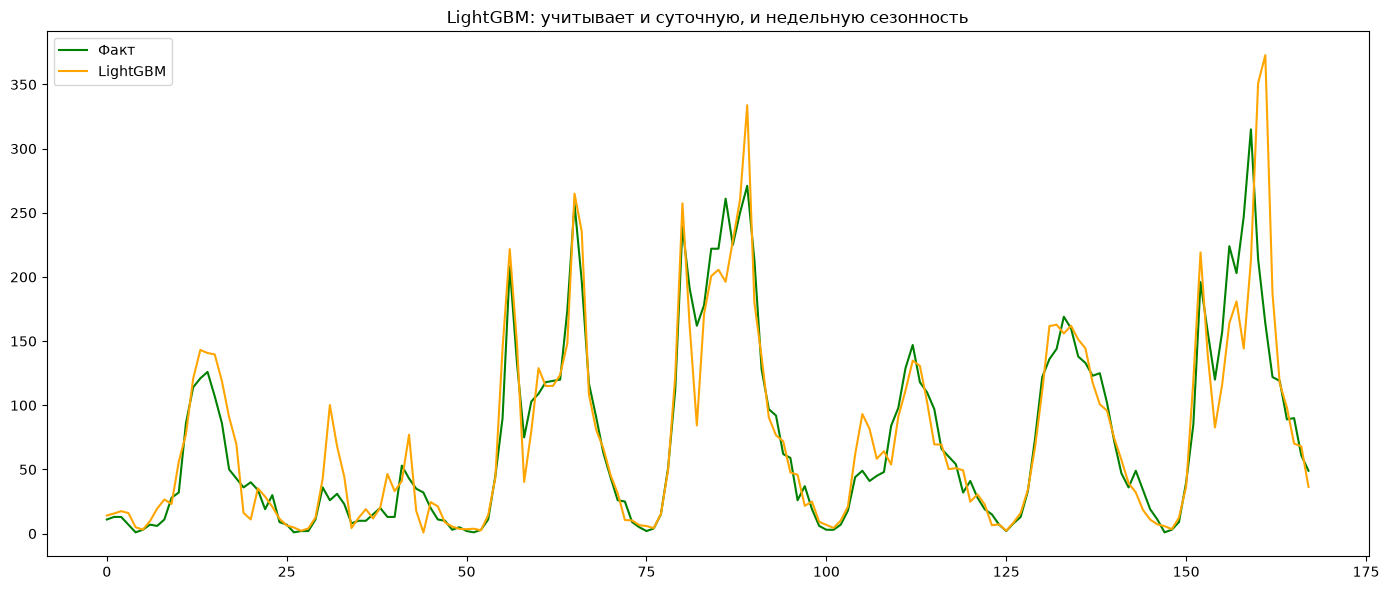


=== Метрики LightGBM ===
MAE:  17.09
RMSE: 30.35
MAPE: 0.44%


In [6]:
import lightgbm as lgb

# Feature Engineering
df['hour_sin'] = np.sin(2 * np.pi * df['hr'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hr'] / 24)
df['is_rush_hour'] = ((df['hr'].isin([7,8,9,17,18,19])) & (df['workingday']==1)).astype(int)
df['is_weekend'] = df['weekday'].isin([5,6]).astype(int)

# Лаги — ключ к успеху!
df['lag_1'] = df['cnt'].shift(1)
df['lag_24'] = df['cnt'].shift(24)    # Тот же час вчера
df['lag_168'] = df['cnt'].shift(168)  # Тот же час неделю назад
df['rolling_mean_24'] = df['cnt'].shift(1).rolling(24).mean()

df = df.dropna()

features = ['season','yr','mnth','hr','holiday','weekday','workingday','weathersit',
            'temp','atemp','hum','windspeed','hour_sin','hour_cos',
            'is_rush_hour','is_weekend','lag_1','lag_24','lag_168','rolling_mean_24']

X = df[features]
y = df['cnt']

split_idx = len(df) - 168
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

train_data = lgb.Dataset(X_train, label=y_train)
params = {'objective':'regression','metric':'rmse','learning_rate':0.05,
          'num_leaves':31,'verbose':-1}

model_lgb = lgb.train(params, train_data, num_boost_round=500)
y_pred = model_lgb.predict(X_test)

plt.figure(figsize=(14, 6))
plt.plot(y_test.values, label='Факт', color='green')
plt.plot(y_pred, label='LightGBM', color='orange')
plt.title('LightGBM: учитывает и суточную, и недельную сезонность')
plt.legend()
plt.tight_layout()
plt.show()

# 5. Оценка качества
mae_LGBM = mean_absolute_error(y_test, y_pred)
rmse_LGBM = root_mean_squared_error(y_test, y_pred)
mape_LGBM = mean_absolute_percentage_error(y_test, y_pred)

print(f"\n=== Метрики LightGBM ===")
print(f'MAE:  {mae_LGBM:.2f}')
print(f'RMSE: {rmse_LGBM:.2f}')
print(f'MAPE: {mape_LGBM:.2f}%')


Train: 17043 часов, Test: 168 часов
Признаков: 20
X_train shape: (16995, 48, 20)
y_train shape: (16995, 1)


Архитектура модели:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 48, 20)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 48, 256)        │       152,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_layer                 │ (None, 256)            │           304 │
│ (AttentionLayer)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 171,441 (669.69 KB)

 Trainable params: 171,441 (669.69 KB)

 Non-trainable params: 0 (0.00 B)


Количество параметров: 171,441

Начинаем обучение...
Epoch 1/200
266/266 ━━━━━━━━━━━━━━━━━━━━ 30s 100ms/step - loss: 0.0363 - mae: 0.1447 - val_loss: 0.0067 - val_mae: 0.0704 - learning_rate: 5.0000e-04
Epoch 2/200
266/266 ━━━━━━━━━━━━━━━━━━━━ 33s 123ms/step - loss: 0.0313 - mae: 0.1348 - val_loss: 0.0071 - val_mae: 0.0762 - learning_rate: 5.0000e-04
Epoch 3/200
266/266 ━━━━━━━━━━━━━━━━━━━━ 28s 106ms/step - loss: 0.0220 - mae: 0.1085 - val_loss: 0.0063 - val_mae: 0.0623 - learning_rate: 5.0000e-04
Epoch 4/200
266/266 ━━━━━━━━━━━━━━━━━━━━ 27s 100ms/step - loss: 0.0174 - mae: 0.0935 - val_loss: 0.0062 - val_mae: 0.0640 - learning_rate: 5.0000e-04
Epoch 5/200
266/266 ━━━━━━━━━━━━━━━━━━━━ 22s 82ms/step - loss: 0.0150 - mae: 0.0856 - val_loss: 0.0045 - val_mae: 0.0546 - learning_rate: 5.0000e-04
Epoch 6/200
266/266 ━━━━━━━━━━━━━━━━━━━━ 41s 153ms/step - loss: 0.0132 - mae: 0.0796 - val_loss: 0.0077 - val_mae: 0.0722 - learning_rate: 5.0000e-04
Epoch 7/200
266/266 ━━━━━━━━━━━━━━━━━━━━ 149s 5

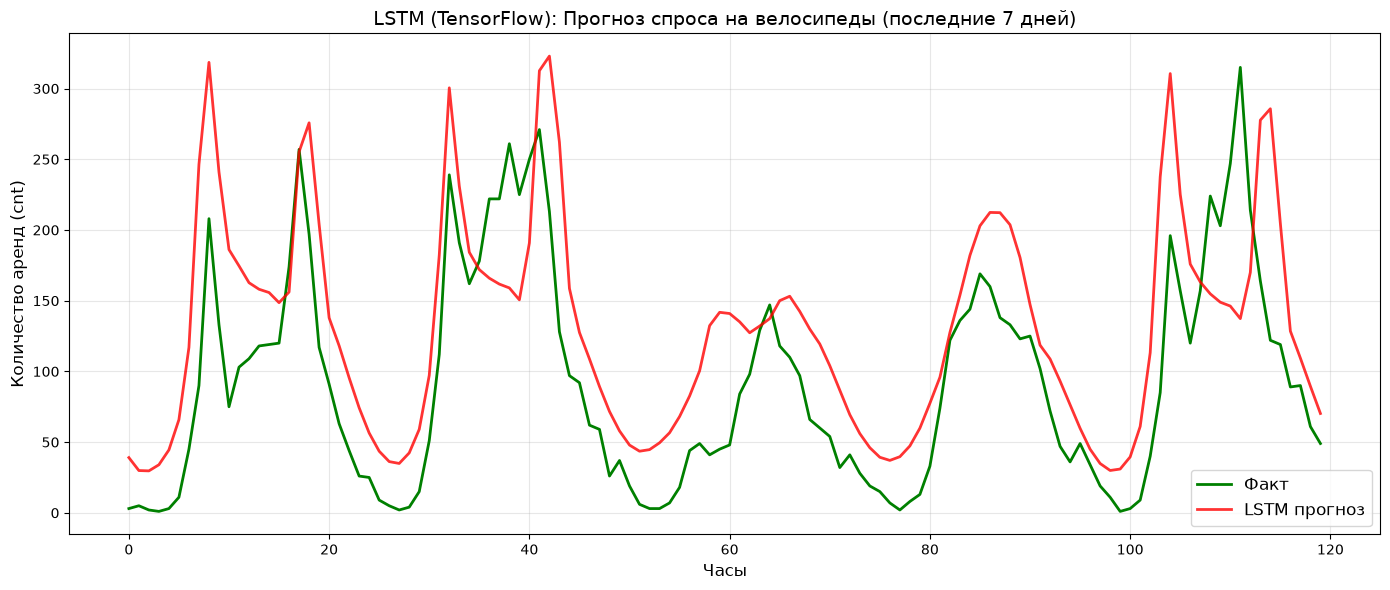

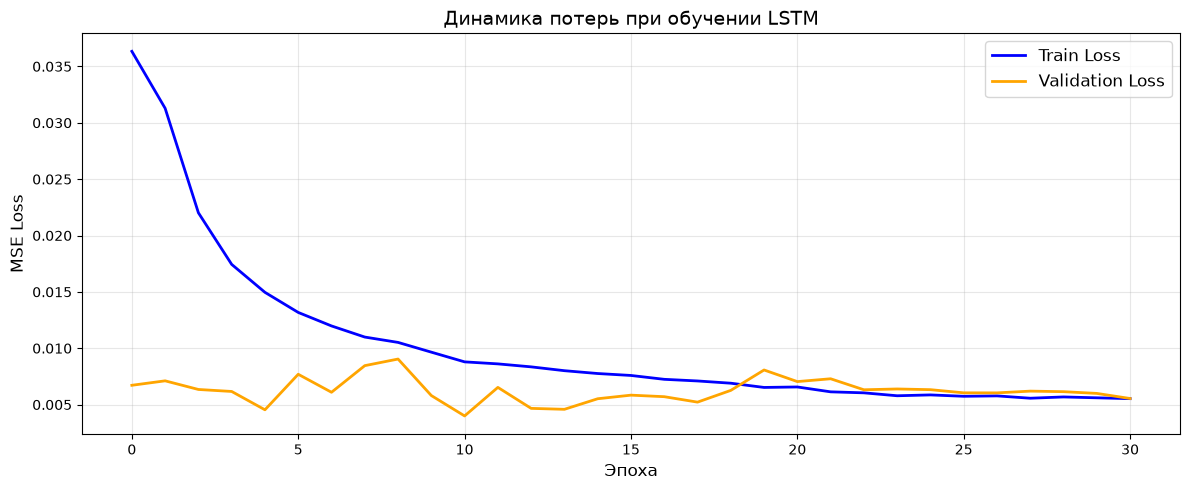

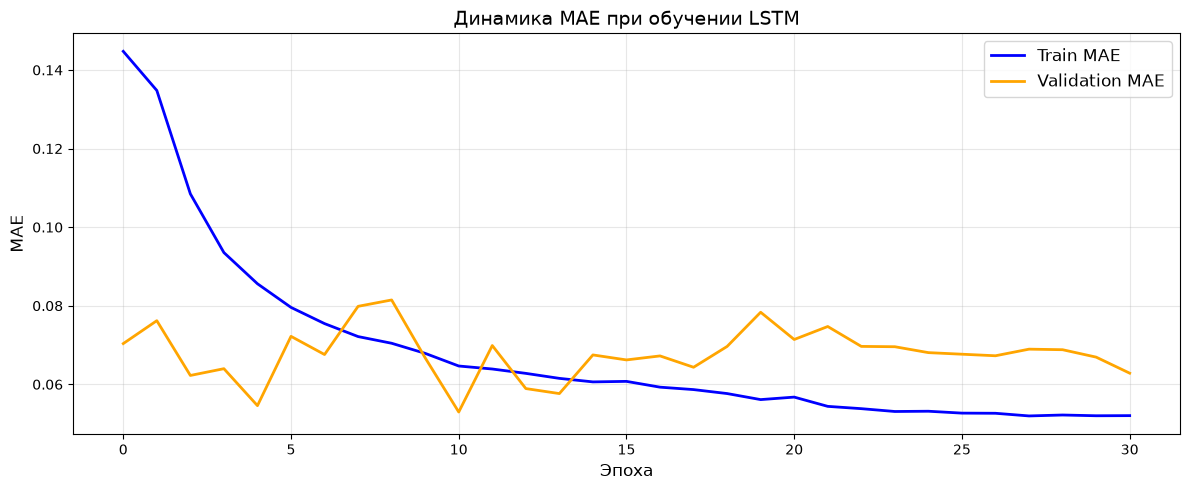

In [7]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Layer, Dense, Dropout, Bidirectional, LSTM, Input
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error

# Для воспроизводимости результатов
np.random.seed(42)
tf.random.set_seed(42)

# ============================================
# 1. ПОДГОТОВКА ДАННЫХ
# ============================================

df = pd.read_csv('hour.csv')
df['datetime'] = pd.to_datetime(df['dteday']) + pd.to_timedelta(df['hr'], unit='h')
df = df.sort_values('datetime').reset_index(drop=True)

# Циклическое кодирование времени
df['hour_sin'] = np.sin(2 * np.pi * df['hr'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hr'] / 24)
df['weekday_sin'] = np.sin(2 * np.pi * df['weekday'] / 7)
df['weekday_cos'] = np.cos(2 * np.pi * df['weekday'] / 7)
df['month_sin'] = np.sin(2 * np.pi * df['mnth'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['mnth'] / 12)

# Бинарные флаги
df['is_rush_hour'] = ((df['hr'].isin([7, 8, 9, 17, 18, 19])) & (df['workingday'] == 1)).astype(float)
df['is_weekend'] = df['weekday'].isin([5, 6]).astype(float)

# 1.3 Лаговые признаки (КРИТИЧЕСКИ ВАЖНО для улучшения)
# Сдвигаем на 24 часа (вчера) и 168 часов (неделю назад)
df['lag_24'] = df['cnt'].shift(24)
df['lag_168'] = df['cnt'].shift(168)

# Удаляем первые 168 строк, где лаги равны NaN
df = df.dropna().reset_index(drop=True)

# Выбираем признаки
feature_cols = [
    'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 
    'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
    'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos', 
    'month_sin', 'month_cos', 'is_rush_hour', 'is_weekend'
]

target_col = 'cnt'

# ============================================
# 2. НОРМАЛИЗАЦИЯ
# ============================================

scaler_features = MinMaxScaler(feature_range=(0, 1))
scaler_target = MinMaxScaler(feature_range=(0, 1))

features_scaled = scaler_features.fit_transform(df[feature_cols])
target_scaled = scaler_target.fit_transform(df[[target_col]])

# Разделение на train/test (последние 168 часов = 7 дней)
test_size = 168
train_size = len(df) - test_size

features_train = features_scaled[:train_size]
features_test = features_scaled[train_size:]
target_train = target_scaled[:train_size]
target_test = target_scaled[train_size:]

print(f"Train: {train_size} часов, Test: {test_size} часов")
print(f"Признаков: {len(feature_cols)}")

# ============================================
# 3. СОЗДАНИЕ ПОСЛЕДОВАТЕЛЬНОСТЕЙ
# ============================================

SEQUENCE_LENGTH = 48  # Смотрим на последние 48 часов

def create_sequences(features, target, seq_length):
    X, y = [], []
    for i in range(len(features) - seq_length):
        X.append(features[i:i + seq_length])
        y.append(target[i + seq_length])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(features_train, target_train, SEQUENCE_LENGTH)
X_test, y_test = create_sequences(features_test, target_test, SEQUENCE_LENGTH)

print(f"X_train shape: {X_train.shape}")  # (samples, seq_length, features)
print(f"y_train shape: {y_train.shape}")

# ============================================
# 4. АРХИТЕКТУРА LSTM МОДЕЛИ (Keras)
# ============================================
# ============================================
# 3. КАСТОМНЫЙ СЛОЙ ATTENTION (ВНИМАНИЕ)
# ============================================

class AttentionLayer(Layer):
    """Слой внимания, который взвешивает важность каждого временного шага"""
    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)

    def build(self, input_shape):
        # W: веса для вычисления важности каждого шага
        self.W = self.add_weight(name='att_weight', shape=(input_shape[-1], 1), initializer='glorot_uniform')
        # b: смещение
        self.b = self.add_weight(name='att_bias', shape=(input_shape[1], 1), initializer='zeros')
        super(AttentionLayer, self).build(input_shape)

    def call(self, x):
        # x shape: (batch_size, time_steps, features)
        # Вычисляем scores для каждого временного шага
        e = tf.keras.backend.tanh(tf.keras.backend.dot(x, self.W) + self.b)
        # Применяем softmax по оси времени (axis=1), чтобы получить веса (сумма = 1)
        a = tf.keras.backend.softmax(e, axis=1)
        # Умножаем исходные данные на веса и суммируем по времени
        output = x * a
        return tf.keras.backend.sum(output, axis=1)


# ============================================
# 4. АРХИТЕКТУРА МОДЕЛИ (УЛУЧШЕННАЯ)
# ============================================

inputs = Input(shape=(SEQUENCE_LENGTH, len(feature_cols)))

# Bidirectional LSTM читает контекст и вперёд, и назад. return_sequences=True нужен для Attention
lstm_out = Bidirectional(LSTM(128, return_sequences=True, dropout=0.2, recurrent_dropout=0.2))(inputs)

# Слой внимания фокусируется на самых информативных часах (например, t-24)
attention_out = AttentionLayer()(lstm_out)

# Плотные слои для интерпретации признаков
dense1 = Dense(64, activation='relu')(attention_out)
drop1 = Dropout(0.3)(dense1)
dense2 = Dense(32, activation='relu')(drop1)
drop2 = Dropout(0.2)(dense2)

# Выходной слой
outputs = Dense(1)(drop2)

model = Model(inputs=inputs, outputs=outputs)

# Компиляция с немного меньшим learning rate для стабильности
optimizer = keras.optimizers.Adam(learning_rate=0.0005)
model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

print("\nАрхитектура модели:")
model.summary()
print(f"\nКоличество параметров: {model.count_params():,}")

# ============================================
# 5. CALLBACKS (Early Stopping, LR Scheduler)
# ============================================

callbacks = [
    # Остановка при отсутствии улучшений
    EarlyStopping(monitor='val_loss', 
                  patience=20, 
                  restore_best_weights=True,
                  verbose=1),
    
    # Уменьшение learning rate при застое
    ReduceLROnPlateau(monitor='val_loss', 
                      factor=0.5, 
                      patience=10, 
                      min_lr=1e-6,
                      verbose=1),
    
    # Сохранение лучшей модели
    ModelCheckpoint('best_lstm_model.keras', 
                    monitor='val_loss', 
                    save_best_only=True,
                    verbose=0)
]

# ============================================
# 6. ОБУЧЕНИЕ МОДЕЛИ
# ============================================

BATCH_SIZE = 64
NUM_EPOCHS = 200

print("\nНачинаем обучение...")
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=NUM_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

# ============================================
# 7. ПРОГНОЗ И ОЦЕНКА
# ============================================

# Прогноз на тестовых данных
predictions_scaled = model.predict(X_test)

# Обратная нормализация
predictions = scaler_target.inverse_transform(predictions_scaled)
actual = scaler_target.inverse_transform(y_test)

mae_LSTM = mean_absolute_error(actual, predictions)
rmse_LSTM = root_mean_squared_error(actual, predictions)
mape_LSTM = mean_absolute_percentage_error(actual, predictions)

print(f"\n=== Метрики LSTM ===")
print(f'MAE:  {mae_LSTM:.2f}')
print(f'RMSE: {rmse_LSTM:.2f}')
print(f'MAPE: {mape_LSTM:.2f}%')

# ============================================
# 8. ВИЗУАЛИЗАЦИЯ
# ============================================

# График прогноза
plt.figure(figsize=(14, 6))
plt.plot(actual, label='Факт', color='green', linewidth=2)
plt.plot(predictions, label='LSTM прогноз', color='red', linewidth=2, alpha=0.8)
plt.title('LSTM (TensorFlow): Прогноз спроса на велосипеды (последние 7 дней)', fontsize=14)
plt.xlabel('Часы', fontsize=12)
plt.ylabel('Количество аренд (cnt)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# График потерь
plt.figure(figsize=(12, 5))
plt.plot(history.history['loss'], label='Train Loss', color='blue', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
plt.title('Динамика потерь при обучении LSTM', fontsize=14)
plt.xlabel('Эпоха', fontsize=12)
plt.ylabel('MSE Loss', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# График MAE
plt.figure(figsize=(12, 5))
plt.plot(history.history['mae'], label='Train MAE', color='blue', linewidth=2)
plt.plot(history.history['val_mae'], label='Validation MAE', color='orange', linewidth=2)
plt.title('Динамика MAE при обучении LSTM', fontsize=14)
plt.xlabel('Эпоха', fontsize=12)
plt.ylabel('MAE', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================
# 10. СОХРАНЕНИЕ И ЗАГРУЗКА МОДЕЛИ
# ============================================

# Сохранение модели
model.save('bike_sharing_lstm.keras')

# Загрузка модели
# loaded_model = keras.models.load_model('bike_sharing_lstm.h5')

### Выводы

In [8]:
print(f"\n=== Метрики SARIMA ===")
print(f'MAE:  {mae_SARIMA:.2f}')
print(f'RMSE: {rmse_SARIMA:.2f}')
print(f'MAPE: {mape_SARIMA:.2f}%')

print(f"\n=== Метрики LightGBM ===")
print(f'MAE:  {mae_LGBM:.2f}')
print(f'RMSE: {rmse_LGBM:.2f}')
print(f'MAPE: {mape_LGBM:.2f}%')

print(f"\n=== Метрики LSTM ===")
print(f'MAE:  {mae_LSTM:.2f}')
print(f'RMSE: {rmse_LSTM:.2f}')
print(f'MAPE: {mape_LSTM:.2f}%')


=== Метрики SARIMA ===
MAE:  91.59
RMSE: 119.98
MAPE: 6.20%

=== Метрики LightGBM ===
MAE:  17.09
RMSE: 30.35
MAPE: 0.44%

=== Метрики LSTM ===
MAE:  51.69
RMSE: 61.71
MAPE: 2.62%


Градиентный бустинг LightGBM лучше всего справился с предсказанием, самые лучшие метрики, и график очень близок к фактическому